# DriveGuard Lane State Analysis

## 목표
블랙박스 영상의 차선 인지 결과를 이용해 다음 정보를 계산한다.

- 차선 이탈 여부
- 차량 진행 방향
- 좌우 차선 여유 폭
- 현재 차량 상태
- 주의사항
- 결과 영상 저장

## 1. 프로젝트 경로 설정

현재 노트북 위치를 기준으로 `DriveGuard` 프로젝트 루트와  
기존 자율주행 코드가 들어 있는 `ros3_ws` 경로를 설정한다.

In [1]:
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw, ImageFont

DISPLAY_CROP_TOP_RATIO = 0.22
plt

print("Python:", sys.version)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("DriveGuard notebook ready")

Python: 3.10.20 | packaged by Anaconda, Inc. | (main, Jun 11 2026, 15:13:20) [MSC v.1942 64 bit (AMD64)]
OpenCV: 5.0.0
NumPy: 2.2.6
Pandas: 2.3.3
DriveGuard notebook ready


## 2. 기존 라이브러리 경로 등록

`ros3_ws` 내부의 카메라 인지 및 판단·경로계획 라이브러리 위치를 찾고,  
해당 경로를 Python 모듈 검색 경로에 추가한다.

In [2]:
from pathlib import Path
import sys

# 현재 노트북 위치:
# DriveGuard/notebooks/lane_state_analysis.ipynb
NOTEBOOK_DIR = Path.cwd().resolve()

# 노트북을 notebooks 폴더에서 실행한다고 가정
PROJECT_ROOT = NOTEBOOK_DIR.parent
ROS_ROOT = PROJECT_ROOT / "ros3_ws"

print("노트북 위치:", NOTEBOOK_DIR)
print("프로젝트 위치:", PROJECT_ROOT)
print("ros3_ws 위치:", ROS_ROOT)
print("ros3_ws 존재:", ROS_ROOT.exists())

노트북 위치: C:\Users\shine\DriveGuard\notebooks
프로젝트 위치: C:\Users\shine\DriveGuard
ros3_ws 위치: C:\Users\shine\DriveGuard\ros3_ws
ros3_ws 존재: True


## 3. 기존 인지·판단 함수 불러오기

수업에서 사용한 카메라 인지 함수와 판단·경로계획 함수를 import한다.  
이후 차선 검출, 차선 중심 계산, 경로 기울기 계산에 재사용한다.

In [3]:
CAM_LIB = (
    ROS_ROOT
    / "src"
    / "camera_perception_pkg"
    / "camera_perception_pkg"
    / "lib"
)

DEC_LIB = (
    ROS_ROOT
    / "src"
    / "decision_making_pkg"
    / "decision_making_pkg"
    / "lib"
)

SAMPLES = (
    CAM_LIB
    / "Collected_Datasets"
    / "sample_dataset"
)

for path in [CAM_LIB, DEC_LIB]:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

print("CAM_LIB 존재:", CAM_LIB.exists())
print("DEC_LIB 존재:", DEC_LIB.exists())
print("SAMPLES 존재:", SAMPLES.exists())

CAM_LIB 존재: True
DEC_LIB 존재: True
SAMPLES 존재: True


## 4. 핵심 함수 사용 가능 여부 확인

프로젝트에서 사용할 주요 함수들이 정상적으로 불러와졌는지 확인한다.

In [4]:
import camera_perception_func_lib as cam
import decision_making_function_lib as dm

print("카메라 인지 함수 로드 완료")
print("판단·경로계획 함수 로드 완료")


 ____    ___   ____    ____  
|  _ \  / _ \ / ___|  |___ \ 
| |_) || | | |\___ \    __) |
|  _ < | |_| | ___) |  / __/ 
|_| \_\ \___/ |____/  |_____|
                             
    _            _                 
   / \    _   _ | |_   ___         
  / _ \  | | | || __| / _ \  _____ 
 / ___ \ | |_| || |_ | (_) ||_____|
/_/   \_\ \__,_| \__| \___/        
                                   
__     __       _      _        _       
\ \   / /  ___ | |__  (_)  ___ | |  ___ 
 \ \ / /  / _ \| '_ \ | | / __|| | / _   \ V /  |  __/| | | || || (__ | ||  __/
   \_/    \___||_| |_||_| \___||_| \___|  


ROS2 기반 자율주행 설계 및 구현
Sungkyunkwan University Automation Lab.
------------------Authors------------------
Hyeong-Keun Hong <whaihong@g.skku.edu>
Jinsun Lee <with23skku@g.skku.edu>
Siwoo Lee <edenlee@g.skku.edu>
Jae-Wook Jeon <jwjeon@skku.edu>
------------------------------------------

 ____    ___   ____    ____  
|  _ \  / _ \ / ___|  |___ \ 
| |_) || | | |\___ \    __) |
|  _ < | |_| | ___) 

In [5]:
functions_to_check = {
    "bird_convert": cam.bird_convert,
    "roi_rectangle_below": cam.roi_rectangle_below,
    "dominant_gradient": cam.dominant_gradient,
    "get_lane_center": cam.get_lane_center,
    "calculate_slope_between_points": dm.calculate_slope_between_points,
}

for name, func in functions_to_check.items():
    print(f"{name}: {callable(func)}")

bird_convert: True
roi_rectangle_below: True
dominant_gradient: True
get_lane_center: True
calculate_slope_between_points: True


## 5. 샘플 이미지 불러오기

기존 실습 데이터의 `sample01.png`를 불러와 원본 영상이 정상적으로 읽히는지 확인한다.

이미지 경로: C:\Users\shine\DriveGuard\ros3_ws\src\camera_perception_pkg\camera_perception_pkg\lib\Collected_Datasets\sample_dataset\sample01.png
이미지 크기: (480, 640, 3)


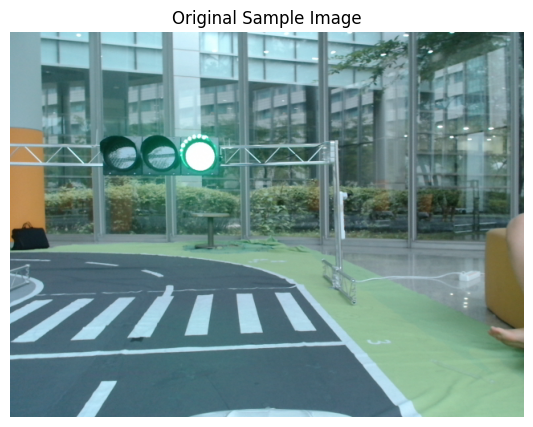

In [6]:
sample_path = SAMPLES / "sample01.png"

img = cv2.imread(str(sample_path))

if img is None:
    raise FileNotFoundError(f"이미지를 불러오지 못했습니다: {sample_path}")

print("이미지 경로:", sample_path)
print("이미지 크기:", img.shape)

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Sample Image")
plt.axis("off")
plt.show()

## 6. 원근 변환(BEV)

블랙박스 시점의 도로 영상을 위에서 내려다본 형태로 변환한다.  
차선의 위치와 폭을 계산하기 쉽게 만드는 단계이다.

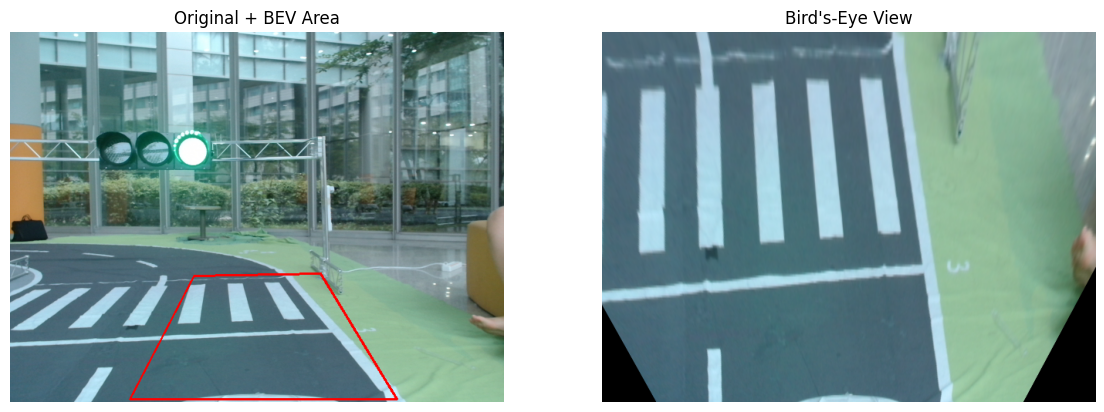

In [7]:
h, w = img.shape[:2]

src_mat = [
    [238, 316],
    [402, 313],
    [501, 476],
    [155, 476],
]

dst_mat = [
    [round(w * 0.3), 0],
    [round(w * 0.7), 0],
    [round(w * 0.7), h],
    [round(w * 0.3), h],
]

bev = cam.bird_convert(
    img,
    srcmat=src_mat,
    dstmat=dst_mat,
)

vis_src = img.copy()
cv2.polylines(
    vis_src,
    [np.int32(src_mat)],
    True,
    (0, 0, 255),
    2,
)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(vis_src, cv2.COLOR_BGR2RGB))
plt.title("Original + BEV Area")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(bev, cv2.COLOR_BGR2RGB))
plt.title("Bird's-Eye View")
plt.axis("off")

plt.show()

## 7. 관심영역(ROI) 추출

BEV 영상에서 차량과 가까운 도로 영역만 남긴다.  
차선 분석에 불필요한 위쪽 영역을 제거한다.

BEV 크기: (480, 640, 3)
ROI 크기: (180, 640, 3)


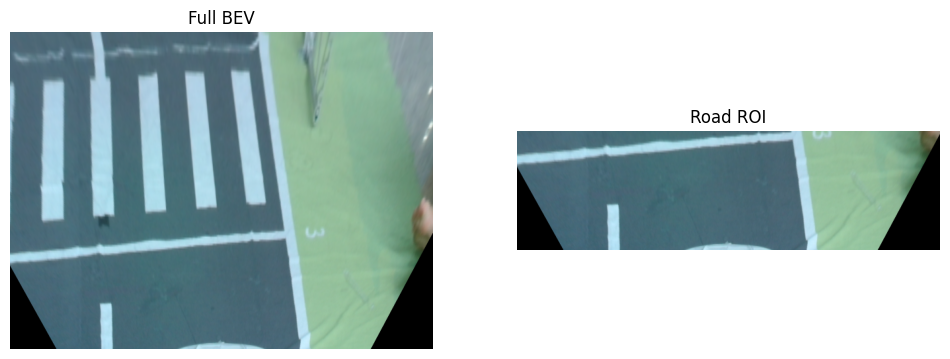

In [8]:
roi = cam.roi_rectangle_below(
    bev,
    cutting_idx=300,
)

print("BEV 크기:", bev.shape)
print("ROI 크기:", roi.shape)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(bev, cv2.COLOR_BGR2RGB))
plt.title("Full BEV")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
plt.title("Road ROI")
plt.axis("off")

plt.show()

## 8. 차선 이진 마스크 생성

ROI 영상을 흑백으로 변환하고 밝은 차선 영역만 추출한다.  
기존 실습에서는 실제 YOLO 차선 세그멘테이션 출력 대신 임계값 기반 이진화를 사용한다.

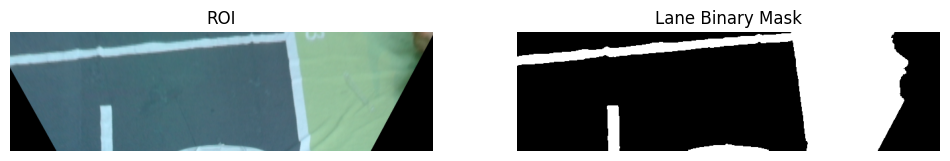

In [9]:
gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)

_, lane_mask = cv2.threshold(
    gray,
    150,
    255,
    cv2.THRESH_BINARY,
)

kernel = np.ones((3, 3), np.uint8)

lane_mask = cv2.morphologyEx(
    lane_mask,
    cv2.MORPH_OPEN,
    kernel,
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
plt.title("ROI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lane_mask, cmap="gray")
plt.title("Lane Binary Mask")
plt.axis("off")

plt.show()

## 9. 차선 대표 기울기 계산

이진 차선 이미지에서 Hough 기반 대표 기울기를 계산한다.  
양수는 오른쪽, 음수는 왼쪽으로 기울어진 방향을 의미한다.

In [10]:
angle = cam.dominant_gradient(
    lane_mask,
    theta_limit=45,
)

print(f"차선 대표 기울기: {angle:.2f}°")

차선 대표 기울기: 1.00°


## 10. 차선 중심 좌표 계산

특정 높이의 차선 픽셀을 이용해 차량이 향해야 할 목표 차선 중심의 x좌표를 계산한다.

In [11]:
mask_h, mask_w = lane_mask.shape[:2]

center_x = cam.get_lane_center(
    lane_mask,
    detection_height=mask_h // 2,
    detection_thickness=10,
    road_gradient=angle,
    lane_width=mask_w,
)

print(f"목표 차선 중심 x: {center_x:.1f}")
print(f"영상 중심 x: {mask_w / 2:.1f}")

목표 차선 중심 x: 639.0
영상 중심 x: 320.0


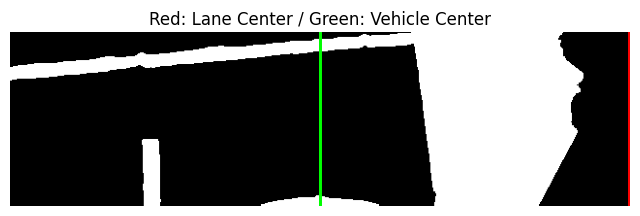

In [12]:
lane_vis = cv2.cvtColor(lane_mask, cv2.COLOR_GRAY2BGR)

# 검출된 차선 중심
cv2.line(
    lane_vis,
    (int(center_x), 0),
    (int(center_x), mask_h),
    (0, 0, 255),
    2,
)

# 영상 중심
cv2.line(
    lane_vis,
    (mask_w // 2, 0),
    (mask_w // 2, mask_h),
    (0, 255, 0),
    2,
)

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(lane_vis, cv2.COLOR_BGR2RGB))
plt.title("Red: Lane Center / Green: Vehicle Center")
plt.axis("off")
plt.show()

## 11. 차선 중심 오차 계산

검출된 차선 중심과 차량 기준 중심의 차이를 계산한다.

- `offset_px = 차선 중심 - 차량 중심`
- 음수: 차선 중심이 차량보다 왼쪽에 있음
- 양수: 차선 중심이 차량보다 오른쪽에 있음

해상도 변화에 대응하기 위해 픽셀값뿐 아니라 영상 폭 대비 비율도 계산한다.

In [13]:
def calculate_lane_offset(
    center_x,
    vehicle_center_x,
    lane_width_px,
):
    """
    차선 중심과 차량 중심의 차이를 차선 폭 기준으로 계산한다.
    """

    if lane_width_px is None or lane_width_px <= 0:
        return {
            "vehicle_center_x": float(vehicle_center_x),
            "lane_center_x": None,
            "offset_px": None,
            "offset_ratio": None,
        }

    offset_px = float(center_x - vehicle_center_x)

    # 영상 전체 폭이 아니라 실제 차선 폭으로 정규화
    offset_ratio = offset_px / lane_width_px

    return {
        "vehicle_center_x": float(vehicle_center_x),
        "lane_center_x": float(center_x),
        "offset_px": offset_px,
        "offset_ratio": offset_ratio,
    }

## 12. 차선 이탈 상태 판단

중심 오차 비율을 이용해 차량 상태를 다음 단계로 분류한다.

- `NORMAL`: 차선 중앙 부근
- `LEFT_WARNING`, `RIGHT_WARNING`: 한쪽 차선에 가까워지는 상태
- `LEFT_DEPARTURE`, `RIGHT_DEPARTURE`: 차선 이탈 위험 상태

임계값은 영상 폭에 대한 비율로 설정하며, 이후 실제 영상 결과를 보면서 조정한다.

In [14]:
def determine_departure_status(
    offset_ratio,
    warning_threshold=0.10,
    departure_threshold=0.25,
):
    """
    차선 폭 대비 중심 편향 비율로 이탈 상태를 판단한다.
    """

    if offset_ratio is None:
        return "LANE_UNCERTAIN"

    abs_offset = abs(offset_ratio)

    if abs_offset < warning_threshold:
        return "NORMAL"

    # 차선 중심이 차량 오른쪽에 있음
    # → 차량은 차로 왼쪽에 치우침
    if offset_ratio > 0:
        if abs_offset < departure_threshold:
            return "LEFT_WARNING"
        return "LEFT_DEPARTURE"

    # 차선 중심이 차량 왼쪽에 있음
    # → 차량은 차로 오른쪽에 치우침
    if abs_offset < departure_threshold:
        return "RIGHT_WARNING"

    return "RIGHT_DEPARTURE"

## 13. 차량 진행 방향 판단

차선 영상에서 계산된 대표 기울기를 이용해 차량의 예상 진행 방향을 판단한다.

- 각도가 0도 부근: 직진
- 음의 각도: 왼쪽 방향
- 양의 각도: 오른쪽 방향

이 값은 실제 차체 자세각이 아니라 영상의 차선 방향을 기준으로 추정한 진행 방향각이다.

In [15]:
def determine_heading_status(
    heading_angle_deg,
    straight_threshold=3.0,
    sharp_threshold=12.0,
):
    """
    차선 대표 기울기를 이용해 진행 방향을 판단한다.

    Parameters
    ----------
    heading_angle_deg : float
        차선 또는 경로의 대표 기울기
    straight_threshold : float
        직진으로 판단할 각도 범위
    sharp_threshold : float
        큰 방향 변화로 판단할 각도 기준

    Returns
    -------
    str
        진행 방향 상태
    """
    angle = float(heading_angle_deg)

    if abs(angle) < straight_threshold:
        return "STRAIGHT"

    if angle < 0:
        if abs(angle) >= sharp_threshold:
            return "SHARP_LEFT"
        return "LEFT"

    if abs(angle) >= sharp_threshold:
        return "SHARP_RIGHT"

    return "RIGHT"


heading_angle_deg = float(angle)

heading_status = determine_heading_status(
    heading_angle_deg
)

print(f"진행 방향각: {heading_angle_deg:.2f}°")
print("진행 방향:", heading_status)

진행 방향각: 1.00°
진행 방향: STRAIGHT


## 14. 좌우 차선 여유 폭 분석

차량 기준 중심을 기준으로 가장 가까운 왼쪽·오른쪽 차선 위치를 찾는다.

검출된 차선 사이의 전체 폭과 차량 양옆의 여유 폭을 계산하여 다음 상태를 판단한다.

- `CENTERED`: 차선 중앙 부근
- `TOO_CLOSE_LEFT`: 왼쪽 차선에 근접
- `TOO_CLOSE_RIGHT`: 오른쪽 차선에 근접
- `OUT_OF_LANE`: 차선 바깥으로 이탈
- `LANE_UNCERTAIN`: 차선 검출 실패

In [16]:
def analyze_lane_margins(
    lane_mask,
    vehicle_center_x,
    reference_y=None,
    band_height=20,
    close_threshold=0.25,
    centered_tolerance=0.10,
):
    """
    차선 마스크에서 차량 좌우의 차선 위치와 여유 폭을 계산한다.

    Parameters
    ----------
    lane_mask : np.ndarray
        차선이 흰색으로 표현된 이진 이미지
    vehicle_center_x : float
        차량 기준 중심의 x 좌표
    reference_y : int or None
        차선 폭을 측정할 기준 y 좌표
    band_height : int
        한 줄이 아닌 일정 높이 구간을 함께 분석
    close_threshold : float
        한쪽 여유 비율이 이 값보다 작으면 차선 근접 상태
    centered_tolerance : float
        좌우 여유 비율 차이가 이 값보다 작으면 중앙 상태

    Returns
    -------
    dict
        좌우 차선 위치, 여유 폭, 여유 비율, 차량 위치 상태
    """
    if lane_mask.ndim != 2:
        raise ValueError("lane_mask는 흑백 이진 이미지여야 합니다.")

    h, w = lane_mask.shape

    if reference_y is None:
        reference_y = h // 2

    reference_y = int(np.clip(reference_y, 0, h - 1))

    y_start = max(0, reference_y - band_height // 2)
    y_end = min(h, reference_y + band_height // 2 + 1)

    # 기준 높이 주변의 차선 픽셀을 세로 방향으로 누적
    band = lane_mask[y_start:y_end, :]
    column_counts = np.count_nonzero(band > 0, axis=0)

    # 분석 구간 높이의 30% 이상 흰색인 열만 차선 후보로 사용
    minimum_count = max(1, int((y_end - y_start) * 0.30))
    candidate_x = np.where(column_counts >= minimum_count)[0]

    left_candidates = candidate_x[candidate_x < vehicle_center_x]
    right_candidates = candidate_x[candidate_x > vehicle_center_x]

    if len(left_candidates) == 0 or len(right_candidates) == 0:
        return {
            "left_lane_x": None,
            "right_lane_x": None,
            "lane_width_px": None,
            "left_margin_px": None,
            "right_margin_px": None,
            "left_margin_ratio": None,
            "right_margin_ratio": None,
            "position_status": "LANE_UNCERTAIN",
            "reference_y": reference_y,
        }

    # 차량 중심에서 가장 가까운 좌우 차선 선택
    left_lane_x = float(left_candidates.max())
    right_lane_x = float(right_candidates.min())

    lane_width_px = right_lane_x - left_lane_x
    left_margin_px = vehicle_center_x - left_lane_x
    right_margin_px = right_lane_x - vehicle_center_x

    if lane_width_px <= 0:
        position_status = "LANE_UNCERTAIN"
        left_margin_ratio = None
        right_margin_ratio = None

    else:
        left_margin_ratio = left_margin_px / lane_width_px
        right_margin_ratio = right_margin_px / lane_width_px

        if left_margin_px <= 0 or right_margin_px <= 0:
            position_status = "OUT_OF_LANE"

        elif left_margin_ratio < close_threshold:
            position_status = "TOO_CLOSE_LEFT"

        elif right_margin_ratio < close_threshold:
            position_status = "TOO_CLOSE_RIGHT"

        elif abs(left_margin_ratio - right_margin_ratio) <= centered_tolerance:
            position_status = "CENTERED"

        elif left_margin_ratio < right_margin_ratio:
            position_status = "LEFT_BIASED"

        else:
            position_status = "RIGHT_BIASED"

    return {
        "left_lane_x": left_lane_x,
        "right_lane_x": right_lane_x,
        "lane_width_px": lane_width_px,
        "left_margin_px": left_margin_px,
        "right_margin_px": right_margin_px,
        "left_margin_ratio": left_margin_ratio,
        "right_margin_ratio": right_margin_ratio,
        "position_status": position_status,
        "reference_y": reference_y,
    }


margin_result = analyze_lane_margins(
    lane_mask=lane_mask,
    vehicle_center_x=mask_w / 2.0,
    reference_y=mask_h // 2,
)

print("좌우 차선 폭 분석 결과")

for key, value in margin_result.items():
    print(f"{key}: {value}")

NameError: name 'offset_result' is not defined

In [ ]:
margin_vis = cv2.cvtColor(lane_mask, cv2.COLOR_GRAY2BGR)

reference_y = margin_result["reference_y"]
vehicle_x = int(offset_result["vehicle_center_x"])

# 측정 기준선
cv2.line(
    margin_vis,
    (0, reference_y),
    (mask_w - 1, reference_y),
    (255, 255, 0),
    1,
)

# 차량 중심
cv2.line(
    margin_vis,
    (vehicle_x, 0),
    (vehicle_x, mask_h - 1),
    (0, 255, 0),
    2,
)

if margin_result["left_lane_x"] is not None:
    left_x = int(margin_result["left_lane_x"])
    right_x = int(margin_result["right_lane_x"])

    # 왼쪽 차선
    cv2.circle(
        margin_vis,
        (left_x, reference_y),
        6,
        (255, 0, 0),
        -1,
    )

    # 오른쪽 차선
    cv2.circle(
        margin_vis,
        (right_x, reference_y),
        6,
        (0, 0, 255),
        -1,
    )

    # 좌우 여유 폭 표시
    cv2.line(
        margin_vis,
        (left_x, reference_y),
        (vehicle_x, reference_y),
        (255, 0, 0),
        3,
    )

    cv2.line(
        margin_vis,
        (vehicle_x, reference_y),
        (right_x, reference_y),
        (0, 0, 255),
        3,
    )

plt.figure(figsize=(9, 5))
plt.imshow(cv2.cvtColor(margin_vis, cv2.COLOR_BGR2RGB))
plt.title(
    f"Lane Margin Analysis: {margin_result['position_status']}"
)
plt.axis("off")
plt.show()

## 15. 전체 차량 상태 및 주의사항 반환

차선 이탈 상태, 진행 방향, 좌우 차선 여유 폭을 통합하여 최종 위험 단계와 운전자 주의사항을 생성한다.

위험 단계는 다음 세 단계로 구분한다.

- `NORMAL`: 정상 주행
- `CAUTION`: 차선 한쪽으로 편향되거나 차선에 근접
- `DANGER`: 차선 이탈 또는 차선 검출 실패

In [ ]:
def determine_risk_and_advice(
    departure_status,
    heading_status,
    position_status,
):
    """
    개별 차선 분석 결과를 통합하여 위험 단계와 주의사항을 생성한다.
    """

    # 1. 차선 검출 실패
    if (
        position_status == "LANE_UNCERTAIN"
        or departure_status == "LANE_UNCERTAIN"
    ):
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "LANE_DETECTION_FAILED",
            "advice": "차선 인식이 불안정합니다. 분석 결과를 주의해서 확인하세요.",
        }

    # 2. 차선 이탈
    if departure_status == "LEFT_DEPARTURE":
        return {
            "risk_level": "DANGER",
            "vehicle_status": "LEFT_DEPARTURE",
            "advice": "왼쪽 차선을 이탈했습니다. 오른쪽으로 안전하게 복귀하세요.",
        }

    if departure_status == "RIGHT_DEPARTURE":
        return {
            "risk_level": "DANGER",
            "vehicle_status": "RIGHT_DEPARTURE",
            "advice": "오른쪽 차선을 이탈했습니다. 왼쪽으로 안전하게 복귀하세요.",
        }

    if position_status == "OUT_OF_LANE":
        return {
            "risk_level": "DANGER",
            "vehicle_status": "OUT_OF_LANE",
            "advice": "차량이 차선 범위를 벗어났습니다. 즉시 차선 안으로 복귀하세요.",
        }

    # 3. 차선 근접 또는 경고
    if departure_status == "LEFT_WARNING":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "LEFT_WARNING",
            "advice": "차량이 왼쪽으로 치우쳤습니다. 오른쪽으로 완만하게 이동하세요.",
        }

    if departure_status == "RIGHT_WARNING":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "RIGHT_WARNING",
            "advice": "차량이 오른쪽으로 치우쳤습니다. 왼쪽으로 완만하게 이동하세요.",
        }

    if position_status == "TOO_CLOSE_LEFT":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "TOO_CLOSE_LEFT",
            "advice": "왼쪽 차선에 가깝습니다. 오른쪽으로 완만하게 이동하세요.",
        }

    if position_status == "TOO_CLOSE_RIGHT":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "TOO_CLOSE_RIGHT",
            "advice": "오른쪽 차선에 가깝습니다. 왼쪽으로 완만하게 이동하세요.",
        }

    if position_status == "LEFT_BIASED":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "LEFT_BIASED",
            "advice": "차량이 차선 왼쪽에 치우쳐 있습니다. 차선 중앙으로 이동하세요.",
        }

    if position_status == "RIGHT_BIASED":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "RIGHT_BIASED",
            "advice": "차량이 차선 오른쪽에 치우쳐 있습니다. 차선 중앙으로 이동하세요.",
        }

    # 4. 급격한 도로 방향 변화
    if heading_status == "SHARP_LEFT":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "SHARP_LEFT_CURVE",
            "advice": "급한 왼쪽 곡선 구간입니다. 속도를 줄이고 방향을 유지하세요.",
        }

    if heading_status == "SHARP_RIGHT":
        return {
            "risk_level": "CAUTION",
            "vehicle_status": "SHARP_RIGHT_CURVE",
            "advice": "급한 오른쪽 곡선 구간입니다. 속도를 줄이고 방향을 유지하세요.",
        }

    # 5. 정상
    return {
        "risk_level": "NORMAL",
        "vehicle_status": "CENTERED",
        "advice": "정상적인 차선 유지 상태입니다.",
    }


final_state = determine_risk_and_advice(
    departure_status=departure_status,
    heading_status=heading_status,
    position_status=margin_result["position_status"],
)

print("최종 차량 상태")
print("위험 단계:", final_state["risk_level"])
print("차량 상태:", final_state["vehicle_status"])
print("주의사항:", final_state["advice"])

## 16. 차선 상태 분석 결과 통합

앞에서 계산한 차선 중심 오차, 진행 방향, 좌우 여유 폭 및 위험 판단 결과를 하나의 데이터 구조로 통합한다.

In [ ]:
lane_analysis_result = {
    # 차선 중심
    "vehicle_center_x": round(
        offset_result["vehicle_center_x"], 1
    ),
    "lane_center_x": round(
        offset_result["lane_center_x"], 1
    ),

    # 차선 이탈
    "offset_px": round(
        offset_result["offset_px"], 1
    ),
    "offset_ratio": round(
        offset_result["offset_ratio"], 3
    ),
    "departure_status": departure_status,

    # 진행 방향
    "heading_angle_deg": round(
        heading_angle_deg, 2
    ),
    "heading_status": heading_status,

    # 좌우 차선 폭
    "left_lane_x": margin_result["left_lane_x"],
    "right_lane_x": margin_result["right_lane_x"],
    "lane_width_px": margin_result["lane_width_px"],
    "left_margin_px": margin_result["left_margin_px"],
    "right_margin_px": margin_result["right_margin_px"],
    "left_margin_ratio": margin_result["left_margin_ratio"],
    "right_margin_ratio": margin_result["right_margin_ratio"],
    "position_status": margin_result["position_status"],

    # 최종 판단
    "risk_level": final_state["risk_level"],
    "vehicle_status": final_state["vehicle_status"],
    "advice": final_state["advice"],
}

lane_analysis_result

## 17. 분석 결과 오버레이

차선 분석 결과를 원본 이미지 위에 시각화한다.

표시 정보:
- 차량 중심선
- 차선 중심선
- 차선 이탈 상태
- 진행 방향각
- 좌우 차선 여유 비율
- 위험 단계
- 주의사항

In [ ]:
def draw_lane_analysis_overlay(
    image,
    analysis_result,
    center_x,
):
    """
    차선 상태 분석 결과를 원본 이미지 위에 표시한다.
    """

    output = image.copy()
    h, w = output.shape[:2]

    # 위험 단계별 표시 색상: BGR
    risk_colors = {
        "NORMAL": (0, 200, 0),
        "CAUTION": (0, 200, 255),
        "DANGER": (0, 0, 255),
    }

    risk_level = analysis_result["risk_level"]
    status_color = risk_colors.get(risk_level, (255, 255, 255))

    # BEV/ROI 좌표와 원본 이미지 좌표가 다르므로
    # 중심 위치는 비율로 원본 이미지 크기에 맞춰 변환
    lane_center_ratio = center_x / mask_w
    lane_center_original_x = int(lane_center_ratio * w)

    vehicle_center_x = w // 2

    # 차량 중심선
    cv2.line(
        output,
        (vehicle_center_x, h),
        (vehicle_center_x, int(h * 0.55)),
        (255, 0, 0),
        3,
    )

    # 검출된 차선 중심선
    cv2.line(
        output,
        (lane_center_original_x, h),
        (lane_center_original_x, int(h * 0.55)),
        (0, 255, 255),
        3,
    )

    # 상단 상태 패널
    overlay = output.copy()

    cv2.rectangle(
        overlay,
        (10, 10),
        (min(w - 10, 620), 245),
        (0, 0, 0),
        -1,
    )

    output = cv2.addWeighted(
        overlay,
        0.65,
        output,
        0.35,
        0,
    )

    def safe_percent(value):
        if value is None:
            return "N/A"
        return f"{value * 100:.1f}%"

    text_lines = [
        f"Risk Level    : {analysis_result['risk_level']}",
        f"Vehicle State : {analysis_result['vehicle_status']}",
        f"Lane Status   : {analysis_result['departure_status']}",
        f"Offset        : {analysis_result['offset_px']:.1f} px",
        f"Heading       : {analysis_result['heading_angle_deg']:.2f} deg",
        f"Direction     : {analysis_result['heading_status']}",
        f"Left Margin   : {safe_percent(analysis_result['left_margin_ratio'])}",
        f"Right Margin  : {safe_percent(analysis_result['right_margin_ratio'])}",
    ]

    y = 40

    for index, text in enumerate(text_lines):
        color = status_color if index == 0 else (255, 255, 255)

        cv2.putText(
            output,
            text,
            (25, y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.58,
            color,
            2,
            cv2.LINE_AA,
        )

        y += 25

    # 화면 하단 위험 경고
    cv2.rectangle(
        output,
        (10, h - 55),
        (w - 10, h - 10),
        status_color,
        -1,
    )

    warning_text = analysis_result["advice"]

    # OpenCV 기본 글꼴은 한글을 표시하지 못하므로
    # 우선 영어 상태 문구를 영상에 출력
    english_advice = {
        "NORMAL": "Lane position is stable.",
        "CAUTION": "Caution: Return gently toward the lane center.",
        "DANGER": "Danger: Check the lane and correct the vehicle position.",
    }

    cv2.putText(
        output,
        english_advice.get(risk_level, warning_text),
        (25, h - 25),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.58,
        (0, 0, 0),
        2,
        cv2.LINE_AA,
    )

    # 차선 중심 보정 방향 표시
    offset_px = analysis_result["offset_px"]

    if abs(offset_px) < 1:
        correction = "KEEP CENTER"
    elif offset_px > 0:
        correction = "MOVE RIGHT"
    else:
        correction = "MOVE LEFT"

    cv2.putText(
        output,
        correction,
        (max(20, w - 220), 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.65,
        status_color,
        2,
        cv2.LINE_AA,
    )

    return output

In [ ]:
overlay_result = draw_lane_analysis_overlay(
    image=img,
    analysis_result=lane_analysis_result,
    center_x=center_x,
)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(overlay_result, cv2.COLOR_BGR2RGB))
plt.title("DriveGuard Lane Analysis Result")
plt.axis("off")
plt.show()

## 18. 결과 이미지 저장

분석 결과가 표시된 이미지를 `outputs/images` 폴더에 저장한다.

In [ ]:
OUTPUT_IMAGE_DIR = PROJECT_ROOT / "outputs" / "images"
OUTPUT_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

output_image_path = OUTPUT_IMAGE_DIR / "lane_analysis_sample01.jpg"

save_success = cv2.imwrite(
    str(output_image_path),
    overlay_result,
)

if not save_success:
    raise RuntimeError("결과 이미지를 저장하지 못했습니다.")

print("결과 이미지 저장 완료")
print("저장 경로:", output_image_path)

In [ ]:
saved_image = cv2.imread(str(output_image_path))

if saved_image is None:
    raise FileNotFoundError(output_image_path)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(saved_image, cv2.COLOR_BGR2RGB))
plt.title("Saved Result Image")
plt.axis("off")
plt.show()

## 19. 프레임 단위 차선 상태 분석

영상의 프레임 한 장에 대해 다음 과정을 한 번에 수행한다.

1. BEV 변환
2. ROI 추출
3. 차선 이진 마스크 생성
4. 차선 중심 및 기울기 계산
5. 차선 이탈 판단
6. 좌우 여유 폭 분석
7. 위험도와 주의사항 생성
8. 분석 결과 오버레이

In [ ]:
def analyze_frame(frame):
    """
    영상 프레임 한 장을 분석하여 결과 영상과 상태값을 반환한다.
    """

    if frame is None or frame.size == 0:
        raise ValueError("비어 있는 프레임입니다.")

    frame_h, frame_w = frame.shape[:2]

    # sample01.png의 기준 해상도: 640 x 480
    base_w = 640
    base_h = 480

    scale_x = frame_w / base_w
    scale_y = frame_h / base_h

    # 원본 실습의 BEV 좌표를 현재 영상 해상도에 맞게 조정
    frame_src_mat = [
        [round(238 * scale_x), round(316 * scale_y)],
        [round(402 * scale_x), round(313 * scale_y)],
        [round(501 * scale_x), round(476 * scale_y)],
        [round(155 * scale_x), round(476 * scale_y)],
    ]

    frame_dst_mat = [
        [round(frame_w * 0.30), 0],
        [round(frame_w * 0.70), 0],
        [round(frame_w * 0.70), frame_h],
        [round(frame_w * 0.30), frame_h],
    ]

    # 1. BEV 변환
    frame_bev = cam.bird_convert(
        frame,
        srcmat=frame_src_mat,
        dstmat=frame_dst_mat,
    )

    # 2. 도로 ROI 추출
    cutting_idx = round(frame_h * (300 / 480))

    frame_roi = cam.roi_rectangle_below(
        frame_bev,
        cutting_idx=cutting_idx,
    )

    # 3. 차선 이진 마스크
    gray = cv2.cvtColor(frame_roi, cv2.COLOR_BGR2GRAY)

    _, frame_lane_mask = cv2.threshold(
        gray,
        150,
        255,
        cv2.THRESH_BINARY,
    )

    kernel = np.ones((3, 3), np.uint8)

    frame_lane_mask = cv2.morphologyEx(
        frame_lane_mask,
        cv2.MORPH_OPEN,
        kernel,
    )

    mask_h, mask_w = frame_lane_mask.shape[:2]

    # 4. 차선 기울기
    frame_angle = cam.dominant_gradient(
        frame_lane_mask,
        theta_limit=45,
    )

    # 차량 기준 중심
    vehicle_center_x = mask_w / 2.0
    
    # 영상 중간보다 조금 아래쪽에서 좌우 차선을 분석
    reference_y = int(mask_h * 0.70)
    
    frame_margin_result = analyze_lane_margins(
    lane_mask=frame_lane_mask,
    vehicle_center_x=vehicle_center_x,
    reference_y=reference_y,
    band_height=max(20, int(mask_h * 0.08)),
    )
    
    # 좌우 차선을 모두 찾은 경우에만 차선 중심 계산
    if (
    frame_margin_result["left_lane_x"] is not None
    and frame_margin_result["right_lane_x"] is not None
    ):
    frame_center_x = (
        frame_margin_result["left_lane_x"]
        + frame_margin_result["right_lane_x"]
    ) / 2.0
    
    frame_offset_result = calculate_lane_offset(
        center_x=frame_center_x,
        vehicle_center_x=vehicle_center_x,
        lane_width_px=frame_margin_result["lane_width_px"],
    )
    
    else:
    frame_center_x = vehicle_center_x
    
    frame_offset_result = {
        "vehicle_center_x": vehicle_center_x,
        "lane_center_x": None,
        "offset_px": None,
        "offset_ratio": None,
    }

    frame_departure_status = determine_departure_status(
        frame_offset_result["offset_ratio"]
    )

    # 7. 진행 방향
    frame_heading_angle = float(frame_angle)

    frame_heading_status = determine_heading_status(
        frame_heading_angle
    )

    # 8. 좌우 여유 폭
    frame_margin_result = analyze_lane_margins(
        lane_mask=frame_lane_mask,
        vehicle_center_x=frame_offset_result["vehicle_center_x"],
        reference_y=mask_h // 2,
    )

    # 9. 최종 위험 상태
    frame_final_state = determine_risk_and_advice(
        departure_status=frame_departure_status,
        heading_status=frame_heading_status,
        position_status=frame_margin_result["position_status"],
    )

    # 10. 전체 결과 통합
    result = {
        "vehicle_center_x": round(
            frame_offset_result["vehicle_center_x"], 1
        ),
        "lane_center_x": (
            round(frame_offset_result["lane_center_x"], 1)
            if frame_offset_result["lane_center_x"] is not None
            else None
        ),
        
        "offset_px": (
            round(frame_offset_result["offset_px"], 1)
            if frame_offset_result["offset_px"] is not None
            else None
        ),
        
        "offset_ratio": (
            round(frame_offset_result["offset_ratio"], 4)
            if frame_offset_result["offset_ratio"] is not None
            else None
        ),
        
        "departure_status": frame_departure_status,

        "heading_angle_deg": round(frame_heading_angle, 2),
        "heading_status": frame_heading_status,

        "left_lane_x": frame_margin_result["left_lane_x"],
        "right_lane_x": frame_margin_result["right_lane_x"],
        "lane_width_px": frame_margin_result["lane_width_px"],
        "left_margin_px": frame_margin_result["left_margin_px"],
        "right_margin_px": frame_margin_result["right_margin_px"],
        "left_margin_ratio": frame_margin_result["left_margin_ratio"],
        "right_margin_ratio": frame_margin_result["right_margin_ratio"],
        "position_status": frame_margin_result["position_status"],

        "risk_level": frame_final_state["risk_level"],
        "vehicle_status": frame_final_state["vehicle_status"],
        "advice": frame_final_state["advice"],
    }

    # 기존 overlay 함수가 전역 mask_w를 사용하지 않도록
    # 프레임 내부에서 사용할 오버레이 구현
    output = draw_video_overlay(
        image=frame,
        analysis_result=result,
        lane_center_x=frame_center_x,
        lane_mask_width=mask_w,
    )

    return output, result, frame_lane_mask

## 20. 영상용 분석 결과 오버레이

프레임마다 계산된 차선 상태를 원본 영상 위에 표시한다.

위험 단계별 표시 색상:
- 초록색: 정상
- 노란색: 주의
- 빨간색: 위험

In [ ]:
def draw_korean_text(
    image,
    text,
    position,
    font_size=30,
    color=(255, 255, 255),
):
    """
    OpenCV 이미지에 한글을 출력한다.
    color는 BGR 형식으로 입력한다.
    """
    font_path = "C:/Windows/Fonts/malgun.ttf"

    if not Path(font_path).exists():
        raise FileNotFoundError(
            "맑은 고딕 글꼴을 찾을 수 없습니다: "
            f"{font_path}"
        )

    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    pil_image = Image.fromarray(rgb_image)
    draw = ImageDraw.Draw(pil_image)
    font = ImageFont.truetype(font_path, font_size)

    # BGR → RGB
    rgb_color = (color[2], color[1], color[0])

    draw.text(
        position,
        text,
        font=font,
        fill=rgb_color,
    )

    return cv2.cvtColor(
        np.array(pil_image),
        cv2.COLOR_RGB2BGR,
    )


def draw_video_overlay(
    image,
    analysis_result,
    lane_center_x,
    lane_mask_width,
):
    """
    도로 영역을 확대하고 분석 결과를 한글로 표시한다.
    """

    original_h, original_w = image.shape[:2]

    # 영상 상단을 잘라 도로 영역 확대
    crop_top = int(original_h * DISPLAY_CROP_TOP_RATIO)

    output = image[crop_top:, :].copy()
    h, w = output.shape[:2]

    risk_colors = {
        "NORMAL": (0, 180, 0),
        "CAUTION": (0, 190, 255),
        "DANGER": (0, 0, 230),
    }

    risk_level = analysis_result["risk_level"]

    status_color = risk_colors.get(
        risk_level,
        (255, 255, 255),
    )

    lane_center_ratio = (
        lane_center_x / lane_mask_width
    )

    lane_center_original_x = int(
        lane_center_ratio * w
    )

    vehicle_center_x = w // 2

    # 차량 중심선
    cv2.line(
        output,
        (vehicle_center_x, h - 1),
        (vehicle_center_x, int(h * 0.55)),
        (255, 0, 0),
        5,
    )

    # 차선 중심선
    cv2.line(
        output,
        (lane_center_original_x, h - 1),
        (lane_center_original_x, int(h * 0.55)),
        (0, 255, 255),
        5,
    )

    # 분석 패널: 영상 폭의 약 38%
    panel_width = int(w * 0.38)
    panel_height = int(h * 0.55)

    panel = output.copy()

    cv2.rectangle(
        panel,
        (20, 20),
        (panel_width, panel_height),
        (0, 0, 0),
        -1,
    )

    output = cv2.addWeighted(
        panel,
        0.78,
        output,
        0.22,
        0,
    )

    def percent_text(value):
        if value is None:
            return "측정 불가"

        return f"{value * 100:.1f}%"

    risk_korean = {
        "NORMAL": "정상",
        "CAUTION": "주의",
        "DANGER": "위험",
    }

    departure_korean = {
        "NORMAL": "정상",
        "LEFT_WARNING": "왼쪽 편향 주의",
        "RIGHT_WARNING": "오른쪽 편향 주의",
        "LEFT_DEPARTURE": "왼쪽 차선 이탈",
        "RIGHT_DEPARTURE": "오른쪽 차선 이탈",
    }

    heading_korean = {
        "STRAIGHT": "직진",
        "LEFT": "왼쪽 진행",
        "RIGHT": "오른쪽 진행",
        "SHARP_LEFT": "급한 왼쪽 방향",
        "SHARP_RIGHT": "급한 오른쪽 방향",
    }

    status_korean = {
        "CENTERED": "차선 중앙",
        "LEFT_WARNING": "왼쪽 편향",
        "RIGHT_WARNING": "오른쪽 편향",
        "TOO_CLOSE_LEFT": "왼쪽 차선 근접",
        "TOO_CLOSE_RIGHT": "오른쪽 차선 근접",
        "LEFT_BIASED": "왼쪽으로 치우침",
        "RIGHT_BIASED": "오른쪽으로 치우침",
        "LEFT_DEPARTURE": "왼쪽 차선 이탈",
        "RIGHT_DEPARTURE": "오른쪽 차선 이탈",
        "OUT_OF_LANE": "차선 범위 이탈",
        "LANE_DETECTION_FAILED": "차선 인식 불안정",
        "SHARP_LEFT_CURVE": "급한 왼쪽 곡선",
        "SHARP_RIGHT_CURVE": "급한 오른쪽 곡선",
    }

    lines = [
        (
            "위험 단계",
            risk_korean.get(risk_level, risk_level),
        ),
        (
            "차량 상태",
            status_korean.get(
                analysis_result["vehicle_status"],
                analysis_result["vehicle_status"],
            ),
        ),
        (
            "차선 상태",
            departure_korean.get(
                analysis_result["departure_status"],
                analysis_result["departure_status"],
            ),
        ),
        (
            "중심 오차",
        (
            f"{analysis_result['offset_px']:.1f} px"
            if analysis_result["offset_px"] is not None
            else "측정 불가"
        )
        (
            "진행 방향각",
            f"{analysis_result['heading_angle_deg']:.2f}°",
        ),
        (
            "진행 방향",
            heading_korean.get(
                analysis_result["heading_status"],
                analysis_result["heading_status"],
            ),
        ),
        (
            "왼쪽 여유",
            percent_text(
                analysis_result["left_margin_ratio"]
            ),
        ),
        (
            "오른쪽 여유",
            percent_text(
                analysis_result["right_margin_ratio"]
            ),
        ),
    ]

    y = 45

    for index, (label, value) in enumerate(lines):
        color = (
            status_color
            if index == 0
            else (255, 255, 255)
        )

        output = draw_korean_text(
            output,
            f"{label} : {value}",
            (40, y),
            font_size=32,
            color=color,
        )

        y += 48

    # 복귀 방향
    offset_px = analysis_result["offset_px"]
    
    if offset_px is None:
        correction = "차선 인식 확인"
    elif abs(offset_px) < 2:
        correction = "차선 중앙 유지"
    elif offset_px > 0:
        correction = "오른쪽으로 이동"
    else:
        correction = "왼쪽으로 이동"

    output = draw_korean_text(
        output,
        correction,
        (w - 350, 35),
        font_size=38,
        color=status_color,
    )

    # 하단 경고 표시
    cv2.rectangle(
        output,
        (20, h - 85),
        (w - 20, h - 20),
        status_color,
        -1,
    )

    advice_korean = {
        "NORMAL": "정상적인 차선 유지 상태입니다.",
        "CAUTION": "주의: 차선 중앙으로 완만하게 복귀하세요.",
        "DANGER": "위험: 즉시 차선을 확인하고 차량 위치를 보정하세요.",
    }

    output = draw_korean_text(
        output,
        advice_korean.get(
            risk_level,
            "현재 차선 상태를 확인하세요.",
        ),
        (45, h - 78),
        font_size=35,
        color=(0, 0, 0),
    )

    return output

## 21. 입력 영상 설정

기존 실습 저장소에 포함된 `driving_simulation.mp4`를 검색하여 입력 영상으로 사용한다.

In [ ]:
input_video_path = (
    PROJECT_ROOT
    / "data"
    / "videos"
    / "blackbox_test1.mp4"
)

if not input_video_path.exists():
    raise FileNotFoundError(
        f"입력 영상을 찾을 수 없습니다: {input_video_path}"
    )

print("입력 영상:", input_video_path)

In [ ]:
cap = cv2.VideoCapture(str(input_video_path))

if not cap.isOpened():
    raise RuntimeError(
        f"영상을 열 수 없습니다: {input_video_path}"
    )

video_fps = cap.get(cv2.CAP_PROP_FPS)
video_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
video_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
video_frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

cap.release()

video_duration = (
    video_frame_count / video_fps
    if video_fps > 0
    else 0
)

print("FPS:", video_fps)
print("해상도:", video_width, "x", video_height)
print("전체 프레임:", video_frame_count)
print(f"영상 길이: {video_duration:.2f}초")

## 22. 전체 영상 분석 및 저장

입력 영상을 프레임 단위로 분석하고 다음 결과를 저장한다.

- 차선 상태가 표시된 MP4 영상
- 프레임별 분석 결과 CSV

In [ ]:
OUTPUT_VIDEO_DIR = PROJECT_ROOT / "outputs" / "videos"
OUTPUT_VIDEO_DIR.mkdir(parents=True, exist_ok=True)

output_video_path = (
    OUTPUT_VIDEO_DIR / "driveguard_analyzed.mp4"
)

output_csv_path = (
    OUTPUT_VIDEO_DIR / "driveguard_frame_results.csv"
)

cap = cv2.VideoCapture(str(input_video_path))

if not cap.isOpened():
    raise RuntimeError("입력 영상을 열지 못했습니다.")

fps = cap.get(cv2.CAP_PROP_FPS)

if fps <= 0:
    fps = 20.0

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

crop_top = int(
    height * DISPLAY_CROP_TOP_RATIO
)

output_height = height - crop_top

writer = cv2.VideoWriter(
    str(output_video_path),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, output_height),
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("결과 영상 Writer 생성 실패")

frame_records = []

frame_index = 0
success_count = 0
failure_count = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    time_sec = frame_index / fps

    try:
        analyzed_frame, result, _ = analyze_frame(frame)

        result_record = {
            "frame": frame_index,
            "time_sec": round(time_sec, 3),
            **result,
            "analysis_success": True,
        }

        success_count += 1

    except Exception as error:
        crop_top = int(
            frame.shape[0] * DISPLAY_CROP_TOP_RATIO
        )
        
        analyzed_frame = frame[crop_top:, :].copy()

        # 분석 실패 프레임 표시
        cv2.rectangle(
            analyzed_frame,
            (10, 10),
            (width - 10, 65),
            (0, 0, 255),
            -1,
        )

        cv2.putText(
            analyzed_frame,
            "LANE ANALYSIS FAILED",
            (25, 48),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.85,
            (255, 255, 255),
            2,
            cv2.LINE_AA,
        )

        result_record = {
            "frame": frame_index,
            "time_sec": round(time_sec, 3),
            "analysis_success": False,
            "error": str(error),
        }

        failure_count += 1

    writer.write(analyzed_frame)
    frame_records.append(result_record)

    frame_index += 1

    # 진행 상황 출력
    if frame_index % 100 == 0:
        print(
            f"{frame_index}/{total_frames} 프레임 처리 완료"
        )

cap.release()
writer.release()

results_df = pd.DataFrame(frame_records)
results_df.to_csv(
    output_csv_path,
    index=False,
    encoding="utf-8-sig",
)

print()
print("영상 분석 완료")
print("성공 프레임:", success_count)
print("실패 프레임:", failure_count)
print("결과 영상:", output_video_path)
print("결과 CSV:", output_csv_path)

## 23. 결과 영상 확인

저장된 결과 영상을 Jupyter Notebook에서 재생하여 분석 결과를 확인한다.

In [ ]:
from IPython.display import Video, display

display(
    Video(
        str(output_video_path),
        embed=True,
        width=800,
    )
)